# 01 — Revenue metrics: MRR, NRR / GRR and why expansion slowed in Q3 2026

**Revenue Analytics · data as of 30 Sep 2026 · synthetic data** (see `docs/data_model.md`)
Request: *"The board wants NRR. Expansion clearly slowed last quarter — why?"* (`docs/01_request_and_scope.md`, questions Q1–Q2)

In [1]:
from saas_rev import marts, theme
from saas_rev.nbutil import md, setup, show
from saas_rev.analysis import metrics as M
from saas_rev.theme import money, pct, pts
setup()
k = M.key_numbers()

## TL;DR

In [2]:
md(f"""
- **ARR {money(k['arr'])}** at 30 Sep 2026 ({k['paying_customers']:,} paying customers), up {pct(k['mrr_yoy_growth'], 0)} year over year — growth is still mostly new logos.
- **12-month NRR {pct(k['nrr_ttm'])}, GRR {pct(k['grr_ttm'])}.** NRR is down {pts(k['nrr_ttm_2026_06'] - k['nrr_ttm']).lstrip('+')} from June
  ({pct(k['nrr_ttm_2026_06'])}), and June was lifted by one customer: excluding the {k['one_off_company']} rollout, NRR is {pct(k['nrr_ttm_ex_one_off'])}.
  The Q3 run-rate (one quarter, annualised) is {pct(k['nrr_runrate_q3_2026'])} vs {pct(k['nrr_runrate_q3_2025'])} a year ago, so the 12-month figure will keep falling if Q3 repeats.
- **Expansion fell {pct(-k['expansion_change_qoq'], 0)} QoQ** ({money(k['expansion_q2_2026'])} → {money(k['expansion_q3_2026'])}). {pct(k['one_off_share_of_q2'], 0)} of Q2's expansion was the one-off rollout.
  Like for like the expansion rate fell from {pct(k['expansion_rate_q2_2026_ex_one_off'])} to {pct(k['expansion_rate_q3_2026'])} of starting MRR, and from {pct(k['expansion_rate_q3_2025'])} a year earlier.
- **Structural drivers (year-over-year bridge):** Technology accounts ({money(k['bridge_yoy']['Technology (all)'])}) and non-Tech plan upgrades
  ({money(k['bridge_yoy']['Non-Tech plan upgrades'])}); non-Tech seat expansion improved ({money(k['bridge_yoy']['Non-Tech seat expansion'])}).
- **Contraction nearly doubled** ({pct(k['contraction_rate_q3_2025'])} → {pct(k['contraction_rate_q3_2026'])} of starting MRR per quarter) — see `04_silent_churn`.
""")


- **ARR $24.8M** at 30 Sep 2026 (4,117 paying customers), up 76% year over year — growth is still mostly new logos.
- **12-month NRR 103.5%, GRR 84.6%.** NRR is down 3.5 pts from June
  (107.0%), and June was lifted by one customer: excluding the Lakewave Payments rollout, NRR is 101.0%.
  The Q3 run-rate (one quarter, annualised) is 92.9% vs 103.6% a year ago, so the 12-month figure will keep falling if Q3 repeats.
- **Expansion fell 33% QoQ** ($94.9K → $63.7K). 28% of Q2's expansion was the one-off rollout.
  Like for like the expansion rate fell from 4.2% to 3.4% of starting MRR, and from 4.9% a year earlier.
- **Structural drivers (year-over-year bridge):** Technology accounts (−$22.3K) and non-Tech plan upgrades
  (−$15.6K); non-Tech seat expansion improved ($9.4K).
- **Contraction nearly doubled** (1.4% → 2.6% of starting MRR per quarter) — see `04_silent_churn`.


## Question
1. What are NRR and GRR, defined the way the board pack will footnote them, and how have they trended?
2. How much did expansion slow in Q3 2026, and how much of the change is a one-off, seasonality, specific segments, fewer plan upgrades vs fewer seat additions?

**Decision it feeds:** the VP's trigger (scope doc §3) — if the Q3 expansion rate excluding the rollout is within 0.5 pt of Q3 2025, call it timing; if it is ≥ 1.0 pt below, re-forecast and name the structural drivers.

## Data
| Table (SQL file) | Grain | Used for |
|---|---|---|
| `fct_customer_mrr_monthly` (`sql/20`) | customer × month-end | MRR, NRR / GRR, cohorts |
| `fct_mrr_movements` (`sql/21`) | customer × month | new / expansion / contraction / churn / reactivation |
| `fct_mrr_movement_components` (`sql/22`) | continuing customer × month | what drove each change (plan, seats, billing, discount) |
| `rpt_mrr_waterfall_monthly`, `rpt_mrr_quarterly` (`sql/23`, `24`) | month / quarter | waterfall and movement rates |
| `rpt_nrr_grr_ttm`, `rpt_nrr_quarterly_runrate` (`sql/25`) | month-end / quarter-end | headline retention |
| `rpt_segment_retention_ttm` (`sql/26`), `rpt_cohort_retention` (`sql/27`) | month × group / cohort × age | segment and cohort views |

Internal / test accounts are excluded; all definitions are in `docs/02_metric_definitions.md`. MRR, movements, NRR and GRR were re-implemented independently in Python and match the SQL to the cent (`docs/03_data_quality_checks.md`).

## Method
- **MRR** = month-end snapshot of each live subscription's price (annual ÷ 12, net of recurring discounts).
- **Movements** compare each customer's MRR with the previous month-end; the monthly identity start + movements = end holds to the cent.
- **NRR / GRR (TTM)**: same customers as 12 months earlier, point-to-point; GRR caps each customer at its starting MRR.
- **Expansion bridge.** Every expanding customer-month goes to exactly one driver bucket — Technology accounts, or non-Tech by the dominant component (seats / plan / other) — so buckets add up. Steps: (1) remove the one-off rollout (a single account worth > 10% of the quarter's expansion, confirmed by Sales); (2) base growth = the earlier quarter's like-for-like rate × this quarter's starting MRR; (3) each bucket's rate change × this quarter's starting MRR. Two bridges: vs Q2 2026 (the VP's framing) and vs Q3 2025 (same season — the primary view for structural drivers).

## Results
### 1. MRR and the monthly waterfall

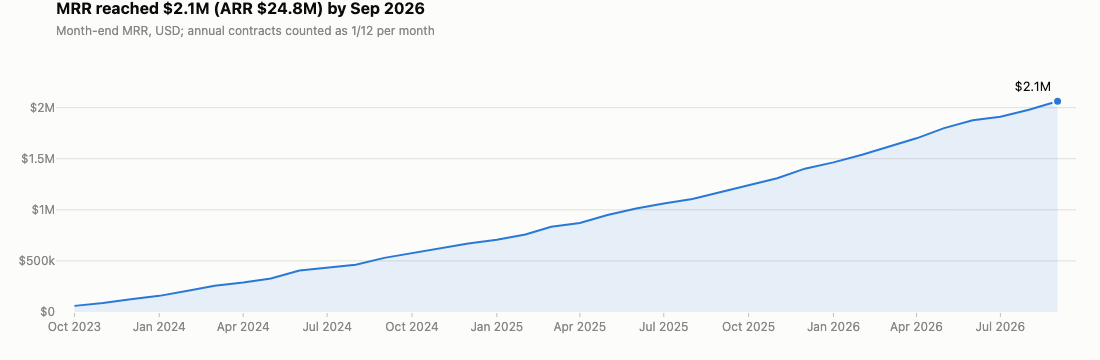

In [3]:
show(M.fig_mrr_trend())

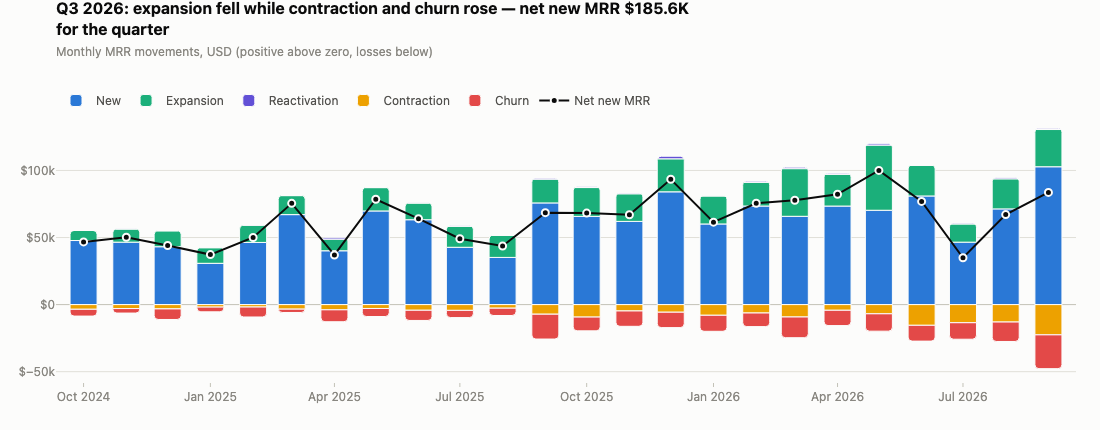

In [4]:
show(M.fig_monthly_movements())

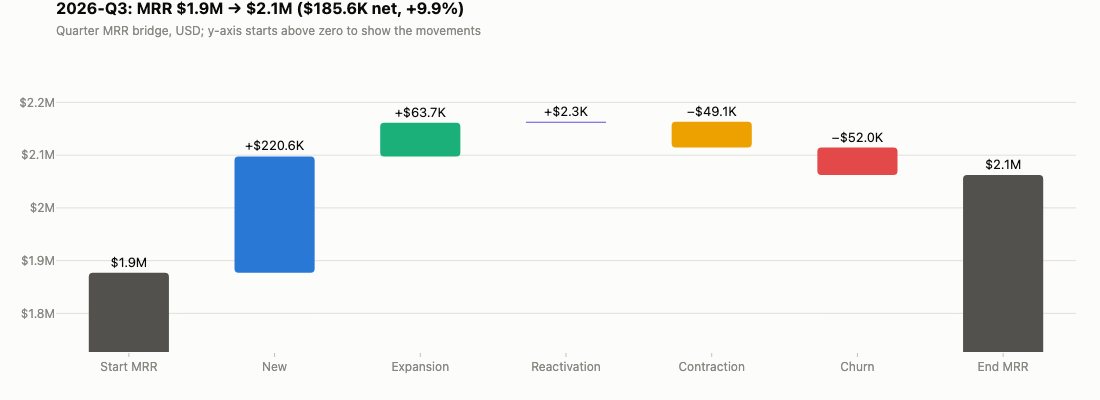

In [5]:
show(M.fig_quarter_waterfall('2026-Q3'))

In [6]:
q = M.quarterly_base()
cols = ['mrr_start_of_quarter', 'new_mrr', 'expansion_mrr', 'reactivation_mrr', 'contraction_mrr', 'churn_mrr',
        'mrr_end_of_quarter', 'expansion_rate', 'contraction_rate', 'churn_rate']
q.loc['2024-Q4':, cols]

,mrr_start_of_quarter,new_mrr,expansion_mrr,reactivation_mrr,contraction_mrr,churn_mrr,mrr_end_of_quarter,expansion_rate,contraction_rate,churn_rate
quarter_label,,,,,,,,,,
2024-Q4,"529,745.4800","137,435.2600","29,149.5200",306.0000,"9,658.2000","16,290.5000","670,687.5600",0.0550,0.0182,0.0308
2025-Q1,"670,687.5600","144,200.0000","38,609.7800",480.0000,"7,076.8800","13,406.9200","833,493.5400",0.0576,0.0106,0.0200
2025-Q2,"833,493.5400","173,204.6000","38,434.6000","1,425.0000","11,006.4100","22,466.0000","1,013,085.3300",0.0461,0.0132,0.0270
2025-Q3,"1,013,085.3300","153,701.1800","49,591.7800","1,480.0000","14,117.3100","29,358.1200","1,174,382.8600",0.0490,0.0139,0.0290
2025-Q4,"1,174,382.8600","211,832.5800","66,663.6200","2,991.0000","19,723.0200","33,187.6400","1,402,959.4000",0.0568,0.0168,0.0283
2026-Q1,"1,402,959.4000","199,391.0800","73,997.2800","2,378.0000","23,454.8000","37,533.2000","1,617,737.7600",0.0527,0.0167,0.0268
2026-Q2,"1,617,737.7600","224,757.4000","94,897.8000","2,166.0000","26,525.0000","36,133.9200","1,876,900.0400",0.0587,0.0164,0.0223
2026-Q3,"1,876,900.0400","220,625.4600","63,726.9600","2,322.0000","49,061.8400","51,967.4800","2,062,545.1400",0.0340,0.0261,0.0277


In [7]:
md(f"""**Reading.** New logos still add about {pct(q.loc['2026-Q3','new_rate'])} of starting MRR a quarter. The change in Q3 is in the existing base:
expansion {pct(q.loc['2025-Q3','expansion_rate'])} → {pct(q.loc['2026-Q3','expansion_rate'])}, contraction {pct(q.loc['2025-Q3','contraction_rate'])} → {pct(q.loc['2026-Q3','contraction_rate'])},
churn {pct(q.loc['2025-Q3','churn_rate'])} → {pct(q.loc['2026-Q3','churn_rate'])} of starting MRR (Q3 2025 → Q3 2026).""")

**Reading.** New logos still add about 11.8% of starting MRR a quarter. The change in Q3 is in the existing base:
expansion 4.9% → 3.4%, contraction 1.4% → 2.6%,
churn 2.9% → 2.8% of starting MRR (Q3 2025 → Q3 2026).

### 2. NRR and GRR

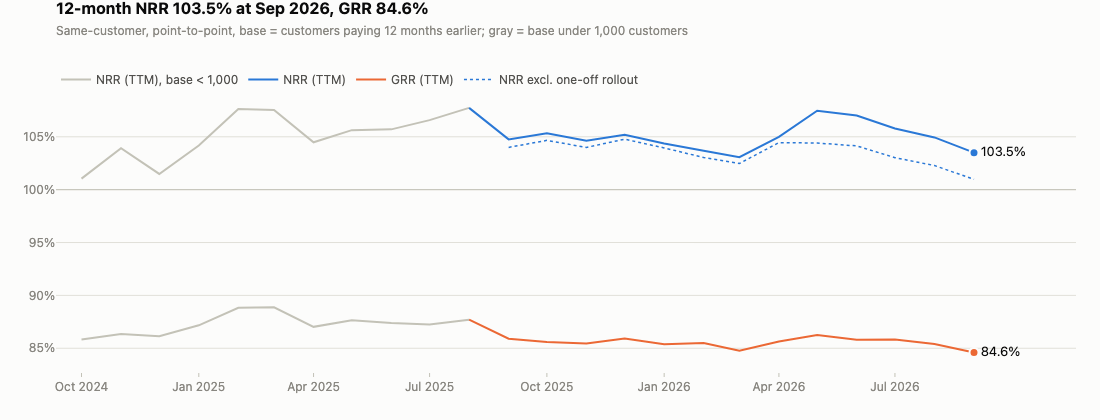

In [8]:
show(M.fig_nrr_trend())

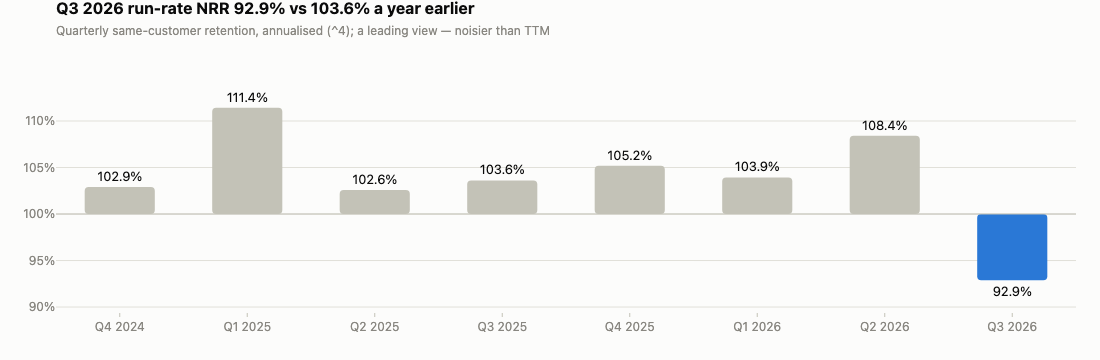

In [9]:
show(M.fig_nrr_runrate())

In [10]:
n = marts.load('rpt_nrr_grr_ttm').set_index('month_end')
n.loc['2025-09-30':, ['base_customers', 'nrr', 'grr', 'logo_retention', 'expansion_contribution', 'contraction_contribution', 'churn_contribution']]

,base_customers,nrr,grr,logo_retention,expansion_contribution,contraction_contribution,churn_contribution
month_end,,,,,,,
2025-09-30,1118,1.0475,0.8590,0.8113,0.1886,-0.0436,-0.0974
2025-10-31,1215,1.0534,0.8560,0.8123,0.1974,-0.0500,-0.0940
2025-11-30,1318,1.0463,0.8544,0.8126,0.1919,-0.0494,-0.0962
2025-12-31,1405,1.0519,0.8591,0.8192,0.1928,-0.0476,-0.0933
2026-01-31,1493,1.0436,0.8538,0.8185,0.1898,-0.0485,-0.0977
2026-02-28,1591,1.0369,0.8549,0.8108,0.1820,-0.0482,-0.0968
2026-03-31,1738,1.0308,0.8476,0.8090,0.1832,-0.0503,-0.1021
2026-04-30,1822,1.0499,0.8564,0.8172,0.1935,-0.0504,-0.0932
2026-05-31,1931,1.0747,0.8624,0.8172,0.2123,-0.0489,-0.0886


In [11]:
md(f"""**Reading.** At 30 Sep 2026 the {k['nrr_base_customers']:,} customers who were paying a year earlier pay {pct(k['nrr_ttm'])} of what they paid then
(GRR {pct(k['grr_ttm'])}). Points before Sep 2025 rest on fewer than 1,000 customers and are shown in gray. The June peak ({pct(k['nrr_ttm_2026_06'])}) includes
one company-wide rollout; without it NRR has drifted from about {pct(k['nrr_ttm_2026_06_ex_one_off'])} (June) to {pct(k['nrr_ttm_ex_one_off'])} (September).""")

**Reading.** At 30 Sep 2026 the 2,377 customers who were paying a year earlier pay 103.5% of what they paid then
(GRR 84.6%). Points before Sep 2025 rest on fewer than 1,000 customers and are shown in gray. The June peak (107.0%) includes
one company-wide rollout; without it NRR has drifted from about 104.1% (June) to 101.0% (September).

### 3. Why expansion slowed — two bridges

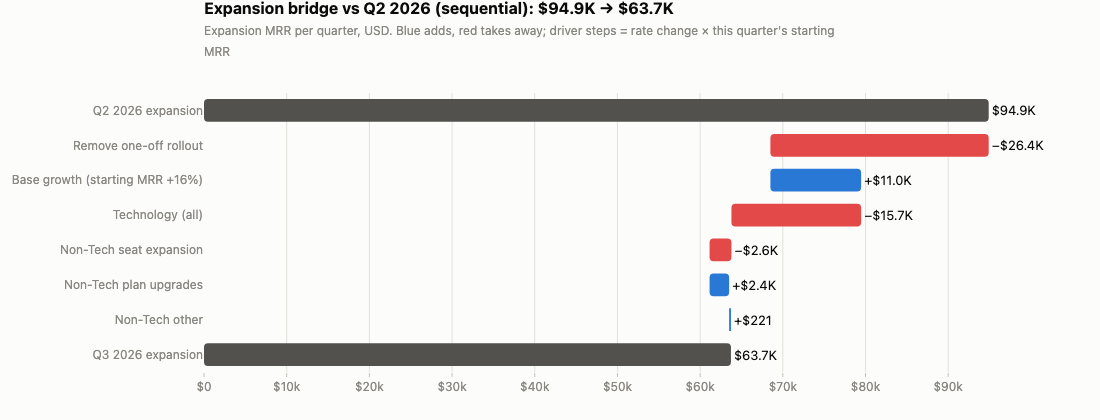

In [12]:
show(M.fig_bridge('qoq'))

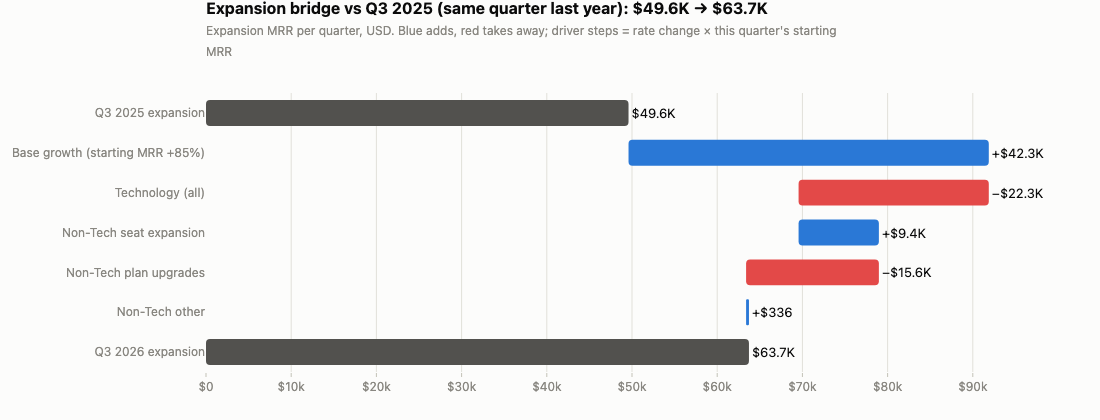

In [13]:
show(M.fig_bridge('yoy'))

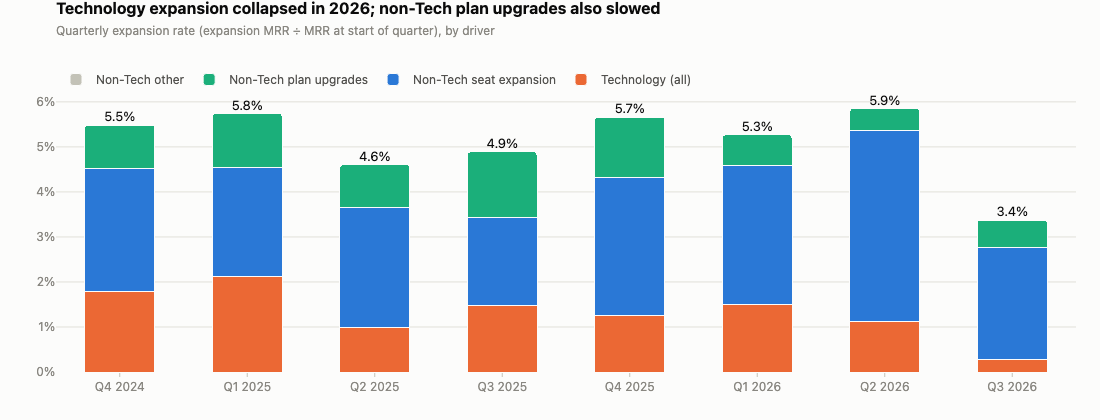

In [14]:
show(M.fig_expansion_rate_by_bucket())

In [15]:
b = marts.load('metrics__bridges')
b[['bridge', 'step', 'value', 'rate_from', 'rate_to']]

,bridge,step,value,rate_from,rate_to
0,2026-Q2 -> 2026-Q3,Q2 2026 expansion,"94,897.8000",NaN,NaN
1,2026-Q2 -> 2026-Q3,Remove one-off rollout,"-26,400.0000",NaN,NaN
2,2026-Q2 -> 2026-Q3,Base growth (starting MRR +16%),"10,973.3768",NaN,NaN
3,2026-Q2 -> 2026-Q3,Technology (all),"-15,685.7671",0.0112,0.0028
4,2026-Q2 -> 2026-Q3,Non-Tech seat expansion,"-2,643.1900",0.0261,0.0247
5,2026-Q2 -> 2026-Q3,Non-Tech plan upgrades,"2,364.1832",0.0049,0.0062
6,2026-Q2 -> 2026-Q3,Non-Tech other,220.5570,0.0001,0.0002
7,2026-Q2 -> 2026-Q3,Q3 2026 expansion,"63,726.9600",NaN,NaN
8,2025-Q3 -> 2026-Q3,Q3 2025 expansion,"49,591.7800",NaN,NaN
9,2025-Q3 -> 2026-Q3,Base growth (starting MRR +85%),"42,284.7985",NaN,NaN


In [16]:
s = M.seasonality_q2_q3()
md(f"""**Reading.**
- *Sequential:* the {money(k['one_off_expansion_mrr'])} rollout at {k['one_off_company']} explains most of the dollar drop. After removing it and allowing for a
  bigger base, Technology accounts take away {money(-k['bridge_qoq']['Technology (all)'])}; non-Tech moved little.
- *Year over year (same season):* the expansion rate fell {pts(k['expansion_rate_q3_2026'] - k['expansion_rate_q3_2025']).lstrip('+')}. Technology accounts
  ({money(k['bridge_yoy']['Technology (all)'])}) and non-Tech plan upgrades ({money(k['bridge_yoy']['Non-Tech plan upgrades'])}) explain it; non-Tech seat
  expansion was *higher* ({money(k['bridge_yoy']['Non-Tech seat expansion'])}). Under the VP's trigger this is **structural** (more than 1.0 pt below Q3 2025).
- *Seasonality:* Q2 → Q3 moved {pts(s.loc[0,'change_pts'])} in 2024 and {pts(s.loc[1,'change_pts'])} in 2025. Two observations cannot separate a summer
  effect from noise; the year-over-year bridge avoids the question.
- The plan-upgrade slowdown is analysed in `02_plan_transitions` (packaging change vs Paid Social mix); the Technology contraction in `04_silent_churn`.""")

**Reading.**
- *Sequential:* the $26.4K rollout at Lakewave Payments explains most of the dollar drop. After removing it and allowing for a
  bigger base, Technology accounts take away $15.7K; non-Tech moved little.
- *Year over year (same season):* the expansion rate fell −1.5 pts. Technology accounts
  (−$22.3K) and non-Tech plan upgrades (−$15.6K) explain it; non-Tech seat
  expansion was *higher* ($9.4K). Under the VP's trigger this is **structural** (more than 1.0 pt below Q3 2025).
- *Seasonality:* Q2 → Q3 moved −0.9 pts in 2024 and +0.3 pts in 2025. Two observations cannot separate a summer
  effect from noise; the year-over-year bridge avoids the question.
- The plan-upgrade slowdown is analysed in `02_plan_transitions` (packaging change vs Paid Social mix); the Technology contraction in `04_silent_churn`.

### 4. Which customer groups retain best

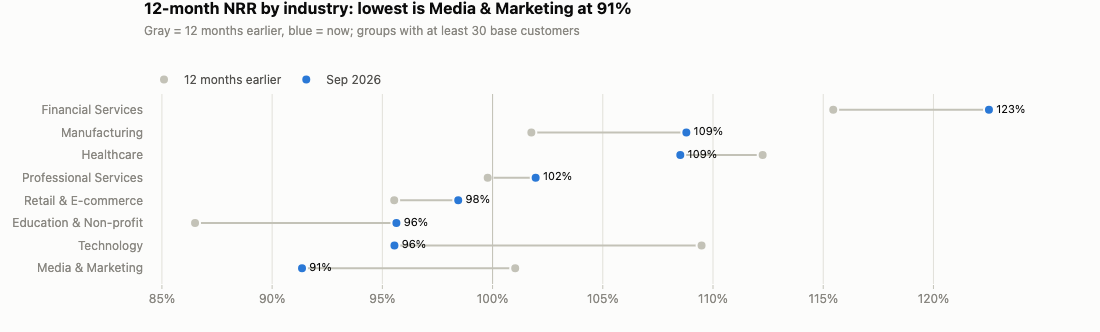

In [17]:
show(M.fig_segment_dumbbell('industry'))

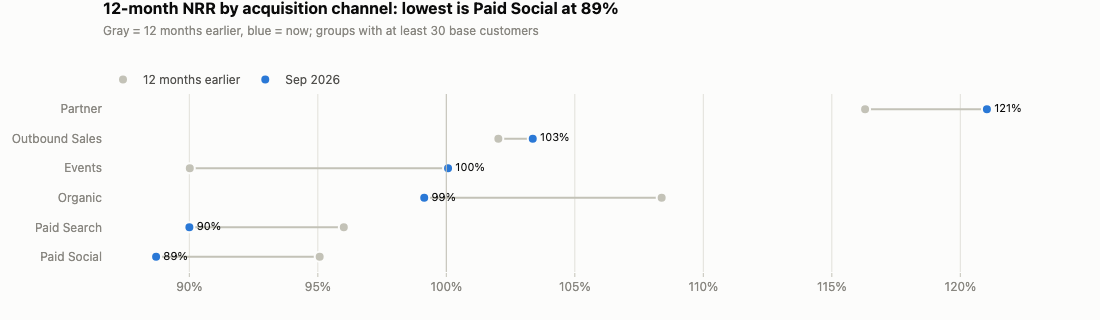

In [18]:
show(M.fig_segment_dumbbell('acquisition_channel'))

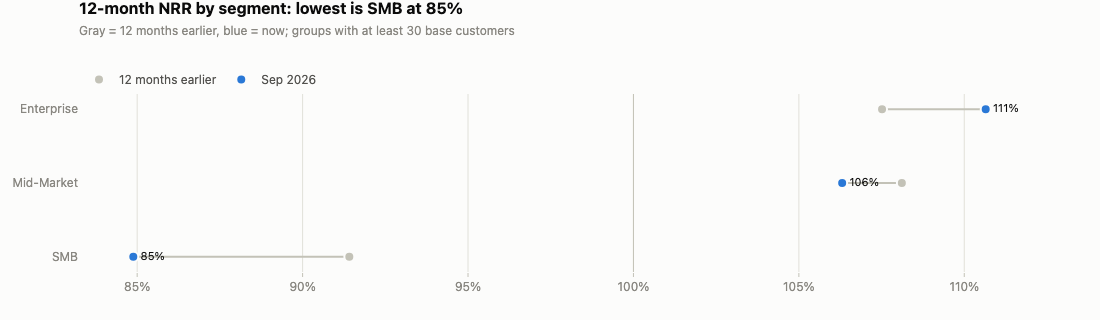

In [19]:
show(M.fig_segment_dumbbell('segment'))

In [20]:
seg = marts.load('metrics__segment_nrr')
seg[['dimension', 'dimension_value', 'base_customers', 'base_mrr', 'nrr', 'grr', 'nrr_year_ago', 'nrr_change']]

,dimension,dimension_value,base_customers,base_mrr,nrr,grr,nrr_year_ago,nrr_change
0,acquisition_channel,Outbound Sales,297,"338,704.5800",1.0336,0.8739,1.0202,0.0134
1,acquisition_channel,Organic,779,"256,959.5000",0.9914,0.8162,1.0838,-0.0924
2,acquisition_channel,Partner,315,"256,532.9000",1.2103,0.8899,1.1629,0.0474
3,acquisition_channel,Paid Search,615,"176,731.0000",0.9000,0.7775,0.9601,-0.0601
4,acquisition_channel,Events,205,"106,363.8800",1.0007,0.8801,0.9002,0.1005
5,acquisition_channel,Paid Social,166,"39,091.0000",0.8871,0.7293,0.9507,-0.0636
6,billing_at_start,annual,1075,"831,029.1600",1.0849,0.8807,1.0909,-0.0060
7,billing_at_start,monthly,1302,"343,353.7000",0.9143,0.7620,0.9458,-0.0315
8,industry,Technology,617,"286,427.8600",0.9555,0.8180,1.0948,-0.1393
9,industry,Financial Services,260,"160,074.5000",1.2252,0.8930,1.1545,0.0706


### 5. Cohorts

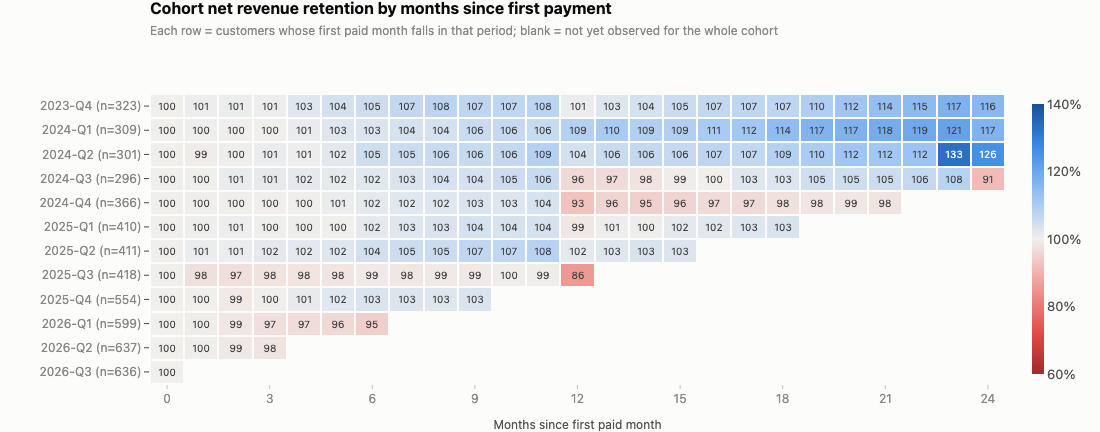

In [21]:
show(M.fig_cohort_heatmap('nrr', 'quarter'))

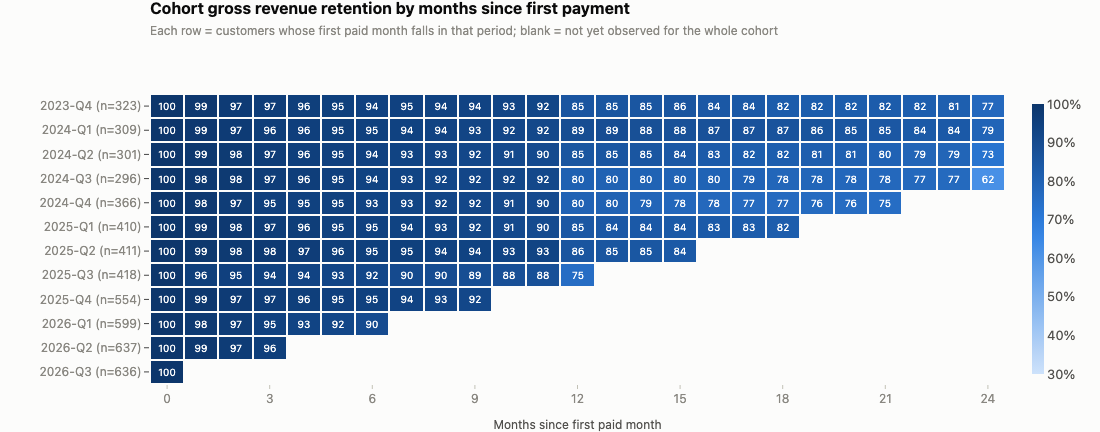

In [22]:
show(M.fig_cohort_heatmap('grr', 'quarter'))

**Reading.** Every cohort dips at month 12 — the first annual renewal, where annual customers right-size seats or leave. Early cohorts (Q4 2023, design partners
and early adopters) keep expanding past 110%; cohorts after the Paid Social launch (Q4 2025 onward) are below 100% within six months. Cohort size is in brackets.

### 6. Top movers in Q3 2026 (for the monthly review)

In [23]:
tm = M.top_movers('2026-Q3', n=8)
tm

,mover_type,customer_id,company_name,segment,industry,csm_owner,mrr_start,mrr_end,amount
0,expansion,CUS-002488,Redframe Wealth,Mid-Market,Financial Services,CSM-08,"2,940.0000","5,490.0000","2,550.0000"
1,expansion,CUS-002117,Primespark Insurance,Mid-Market,Financial Services,CSM-09,"8,008.0000","9,240.0000","1,232.0000"
2,expansion,CUS-002368,Coppergate Studios,SMB,Media & Marketing,NaN,720.0000,"1,575.0000","1,100.0000"
3,expansion,CUS-000162,Falconrock Care,Enterprise,Healthcare,CSM-02,"5,880.0000","6,972.0000","1,092.0000"
4,expansion,CUS-000755,Truelight Components,Mid-Market,Manufacturing,CSM-08,"5,865.0000","6,800.0000",935.0000
5,expansion,CUS-002496,Redport Fabrication,Mid-Market,Manufacturing,CSM-09,552.0000,"1,428.0000",876.0000
6,expansion,CUS-000073,Nextwood Manufacturing,Mid-Market,Manufacturing,CSM-07,"5,590.0000","6,450.0000",860.0000
7,expansion,CUS-003099,Peakstack Medical,Enterprise,Healthcare,CSM-01,"5,031.0000","5,891.0000",860.0000
8,contraction,CUS-001032,Peakcrest Health,Enterprise,Healthcare,CSM-04,"5,561.0000","3,320.0000","2,241.0000"
9,contraction,CUS-001209,Meridianridge Legal,Enterprise,Professional Services,CSM-04,"4,672.0000","3,029.5000","1,642.5000"


## Limitations
- **Synthetic data**: effect sizes come from generator rules (`docs/data_model.md §6`); the method, not the magnitudes, is what transfers.
- **Month-end snapshots** miss customers who start and cancel inside a month and net several changes within a month (counted in the data-quality checks).
- **Bridge attribution** puts each expanding account-month in one bucket by its dominant component; months mixing seat and plan changes are rare but the split there is a choice, not a measurement.
- **Seasonality** rests on two prior years; a third year would be needed to estimate it.
- **Correlation, not causation**: the drop in plan upgrades coincides with the April packaging change and with a Paid Social mix shift — `02_plan_transitions` separates the two as far as the data allows; a holdout test is the only clean answer.

## Recommendations (detail in `05_recommendations`)
1. Board pack: report 12-month NRR with the definition footnote, show NRR excluding the one-off next to it, and add the Q3 run-rate as the leading indicator.
2. Treat the slowdown as structural (VP trigger met): re-forecast Q4 expansion with the Q3 like-for-like rate, and assign owners — CS for Technology accounts, Product for the Basic upgrade path.
3. Keep non-Tech seat expansion plays as they are; they are working.

**What data I would want next:** pipeline / opportunity data for sales-assisted expansion, CRM notes on Technology accounts' headcount plans, and a randomised holdout for any packaging change.